In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import sympy as sp

In [2]:
def F(x, r, N, xc):
    return r*x*(1 - 1/(1 + np.exp(xc - x))
                + x/((1 + np.exp(xc - x))*(N + x)))

def dF_dx(x, r, N, xc, h=1e-6):
    return (F(x+h, r, N, xc) - F(x-h, r, N, xc)) / (2*h)

In [4]:
xc_values = [0.5, 1.5, 2.5, 5, 15, 40, 80]
N_values  = [0.5, 1, 10, 25, 50, 100, 250, 500, 1000]
param_sets = [
    (y,x) for y in N_values for x in xc_values 
]

x_max_map = {1: 10, 25: 20, 0.5: 10, 10: 25, 50: 40, 100: 90, 250: 50, 500: 50, 1000: 50}
r_max_map = {1: 5, 25: 18, 0.5: 4, 10: 14, 50: 10, 100: 16, 250: 50, 500: 85, 1000: 150}
ncols = 4
nrows = int(np.ceil(len(param_sets) / ncols))

# fig, axes = plt.subplots(nrows, ncols, figsize=(16, 55))
# axes = axes.flatten()
# 
# for ax, (N, xc) in zip(axes, param_sets):
#     x_max = x_max_map.get(N, 50)
#     r_max = r_max_map.get(N, 10)
#     x = np.linspace(0, x_max, 500)
#     r = np.linspace(0, r_max, 500)
#     R, X = np.meshgrid(r, x)
# 
#     G = X - F(X, R, N, xc)
#     dF = dF_dx(X, R, N, xc)
#     ax.contour(R, X, G, levels=[0], colors='black', linewidths=2)
#     ax.contour(R, X, dF, levels=[-1], colors='blue', linestyles='dashed')
#     ax.contour(R, X, dF, levels=[1], colors='red', linestyles='dashed')
# 
#     ax.set_title(f"N = {N}, xc = {xc}")
#     ax.set_xlabel("r")
#     ax.set_ylabel("x")
#     ax.grid(True, linestyle=":", alpha=0.6)
# for i in range(len(param_sets), len(axes)):
#     axes[i].axis("off")
# 
# plt.suptitle(
#     "Неявные стационарные кривые G(x,r)=0 и линии F'(x)=±1\n"
#     "Сравнение для различных N и xc",
#     fontsize=16
# )
# plt.tight_layout(rect=[0, 0, 1, 0.93])
# plt.show()

# Для 80-ти везде слишком высоко поднялось, но в целом тенденция понятна. Увеличение $x_c$ поднимает все крючки (синий, красный и черный) выше и приближает к оси $y$ синий крючок.

In [3]:
def F(x, r, N, xc):
    return r*x*(1 - 1/(1 + np.exp(xc - x))
                + x/((1 + np.exp(xc - x))*(N + x)))

def dF_dx(x, r, N, xc, h=1e-6):
    return (F(x+h, r, N, xc) - F(x-h, r, N, xc)) / (2*h)

def plot_stability(param_sets, x_max_map, r_max_map, ncols, x_len, y_len):
    nrows = int(np.ceil(len(param_sets) / ncols))
    
    fig, axes = plt.subplots(nrows, ncols, figsize=(x_len, y_len))
    axes = axes.flatten()
    
    for ax, (N, xc) in zip(axes, param_sets):
        x_max = x_max_map.get(N, 50)
        r_max = r_max_map.get(N, 10)
        x = np.linspace(-2.5, x_max, 500)
        r = np.linspace(0, r_max, 500)
        R, X = np.meshgrid(r, x)
    
        G = X - F(X, R, N, xc)
        dF = dF_dx(X, R, N, xc)
        
        stable = (dF > -1) & (dF < 1)
    
        # ax.contourf(
        #     R, X, stable,
        #     levels=[0.5, 1],
        #     colors=['#ccffe5'],
        #     alpha=0.7
        # )
        # 
        # ax.contour(R, X, G, levels=[0], colors='black', linewidths=2)
        # ax.contour(R, X, dF, levels=[-1], colors='blue', linestyles='dashed')
        # ax.contour(R, X, dF, levels=[1], colors='red', linestyles='dashed')
        
        ax.contourf(
            R, X, stable,
            levels=[0.5, 1],
            colors=['#ccffe5'],
            alpha=0.8
        )

        # ===== КРИВЫЕ =====
        c_stationary = ax.contour(
            R, X, G,
            levels=[0],
            colors='black',
            linewidths=2
        )

        c_minus = ax.contour(
            R, X, dF,
            levels=[-1],
            colors='blue',
            linestyles='dashed'
        )

        c_plus = ax.contour(
            R, X, dF,
            levels=[1],
            colors='red',
            linestyles='dashed'
        )

        # ===== ПОДПИСИ НА ЛИНИЯХ =====
        mask = np.abs(G) < 0.01 * x_max
        i, j = np.argwhere(mask)[len(np.argwhere(mask)) // 2]
        
        ax.text(
            R[i, j], X[i, j], 'x*',
            fontsize=8,
            ha='center',
            va='center',
            bbox=dict(facecolor='white', edgecolor='none', pad=0.3)
        )
        ax.clabel(c_minus, fmt={-1: 'F`=-1'}, fontsize=8)
        ax.clabel(c_plus, fmt={1: 'F`=1'}, fontsize=8)

        # ===== ПОДПИСЬ ВНУТРИ ЗЕЛЁНОЙ ОБЛАСТИ =====
        # выбираем точку, где stable == True
        idx = np.argwhere(stable)
        if idx.size > 0:
            i, j = idx[len(idx) // 2]
            ax.text(
                R[i, j], X[i, j], '|F`|<1',
                fontsize=8,
                color='black',
                ha='center',
                va='center'
            )
    
        ax.set_title(f"xc = {xc}, N = {N}")
        ax.set_xlabel("r")
        ax.set_ylabel("x")
        ax.grid(True, linestyle=":", alpha=0.6)
    for i in range(len(param_sets), len(axes)):
        axes[i].axis("off")
    
    # plt.suptitle(
    #     "Неявные стационарные кривые G(x,r)=0 и область |F'(x)| < 1\n"
    #     "Сравнение для различных N и xc",
    #     fontsize=16
    # )
    plt.tight_layout(rect=[0, 0, 1, 0.93])
    plt.show()

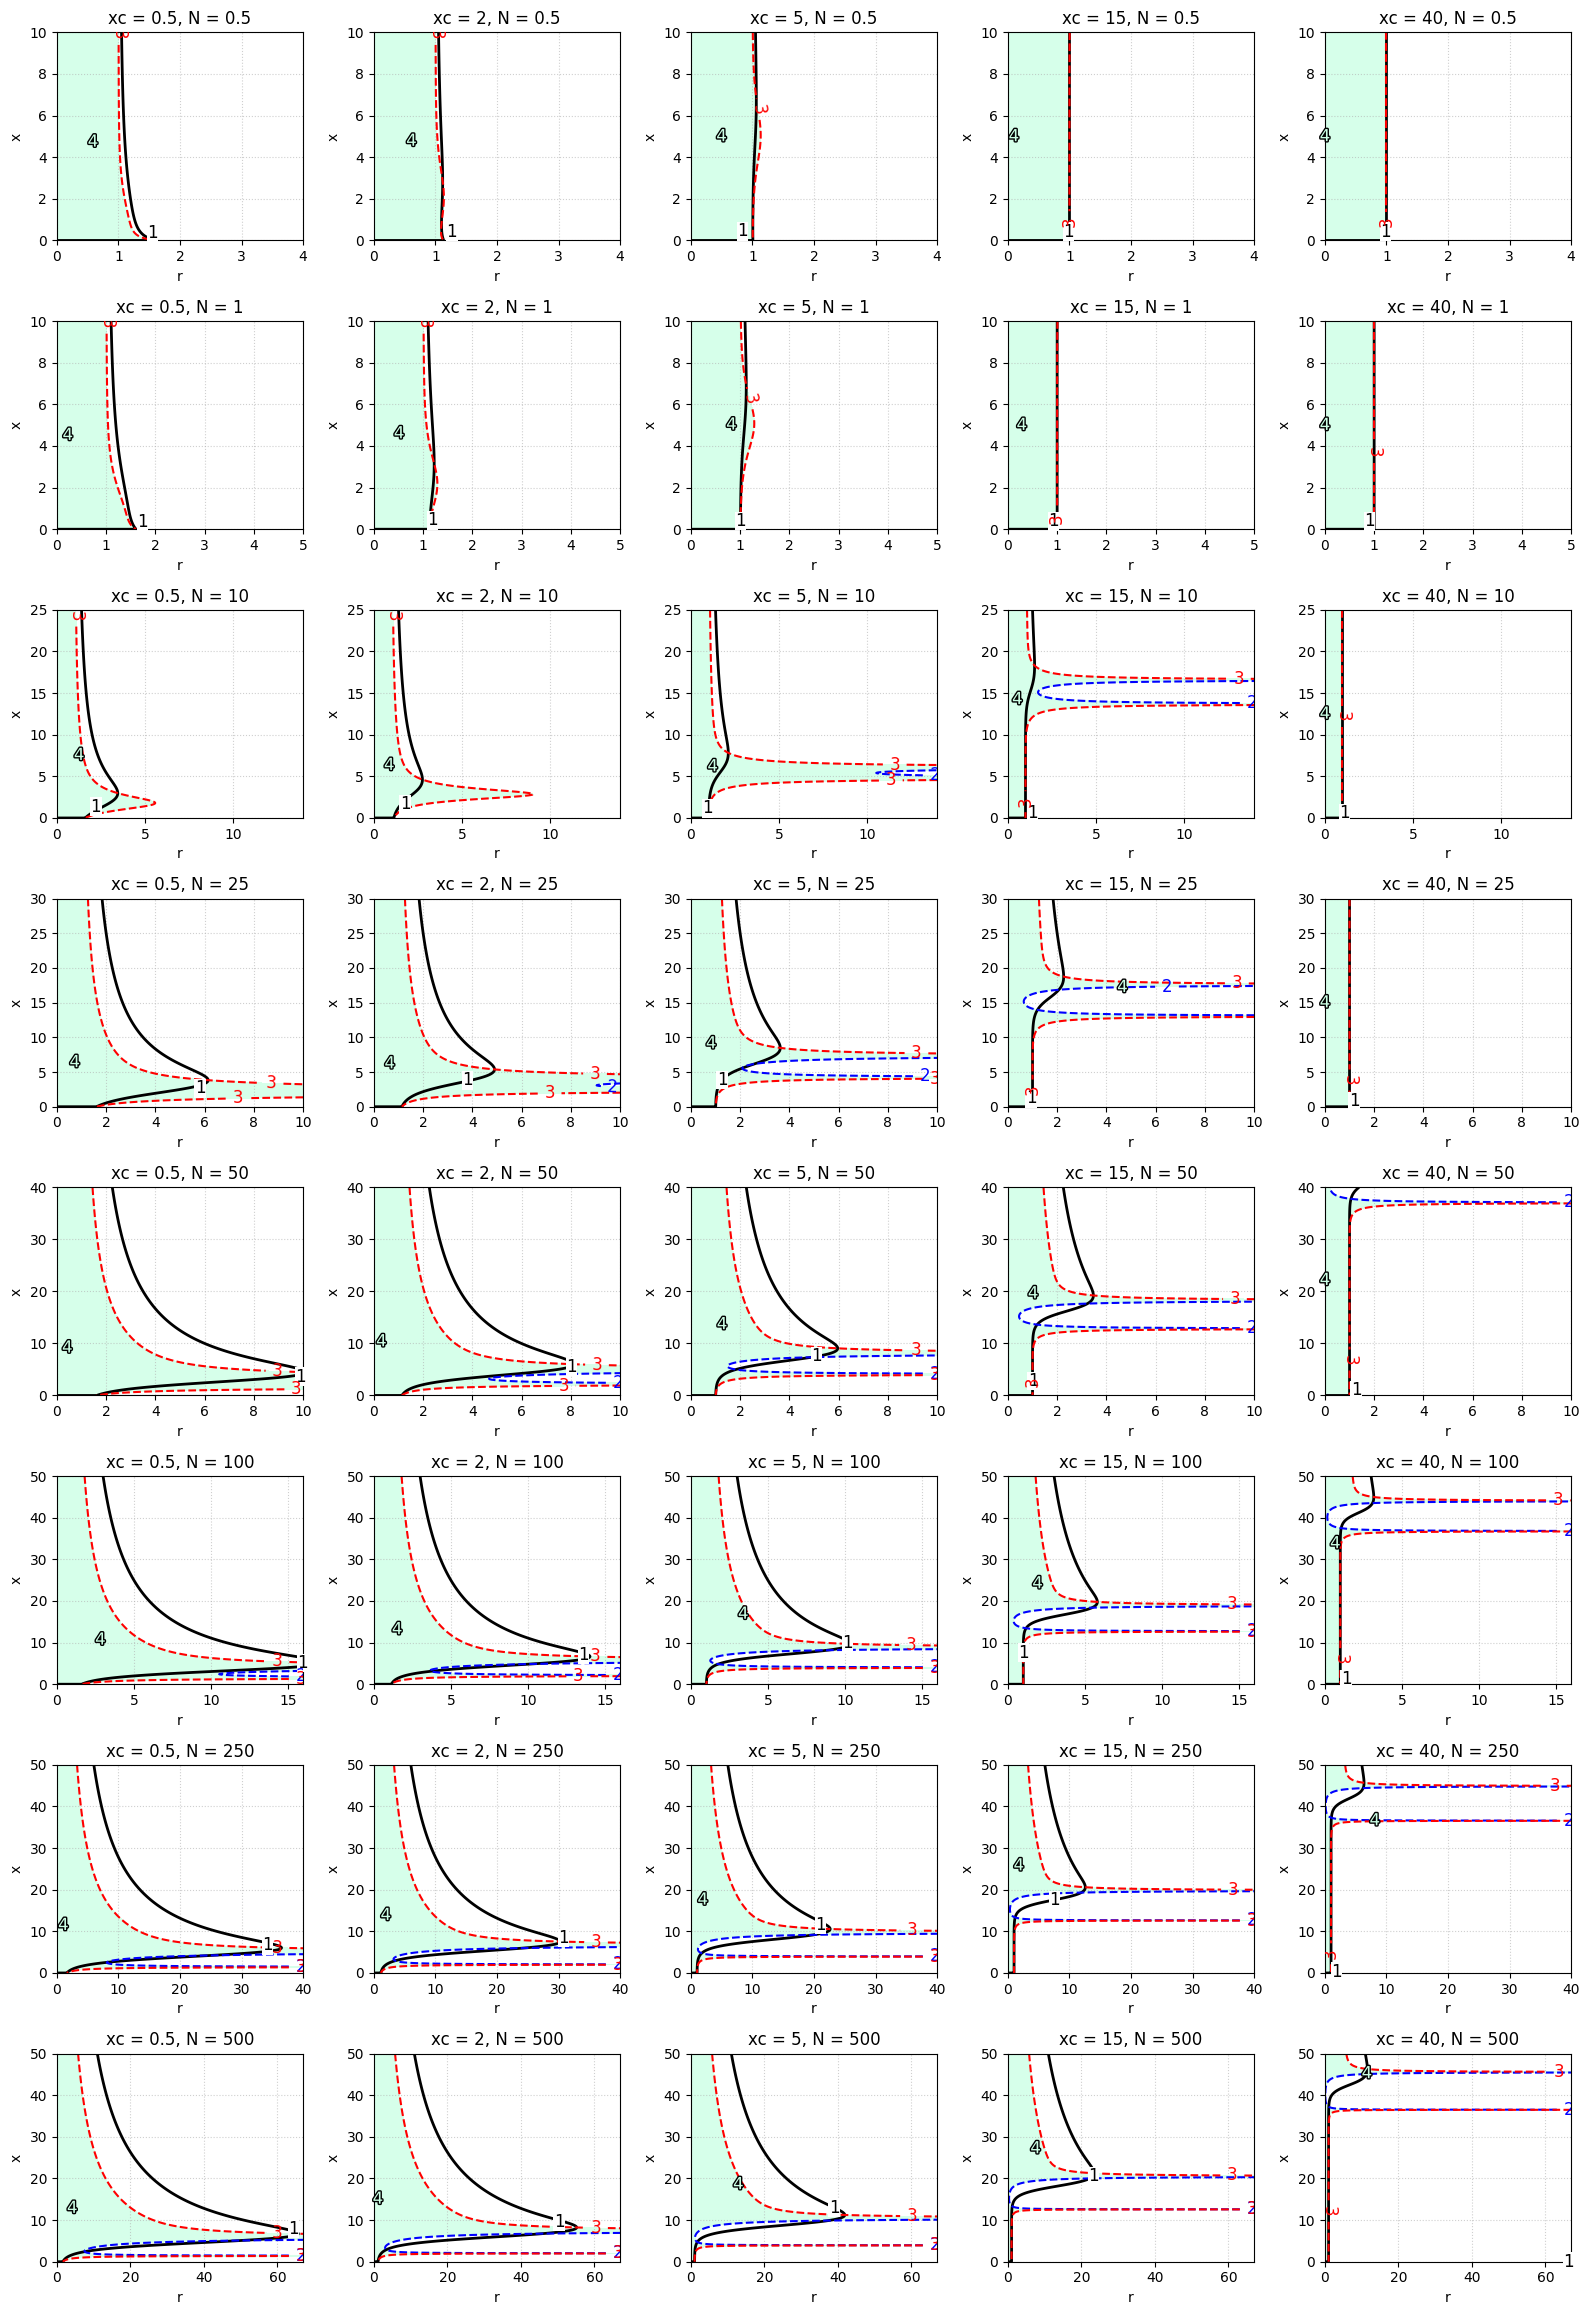

In [212]:
xc_values = [0.5, 2, 5, 15, 40]
N_values  = [0.5, 1, 10, 25, 50, 100, 250, 500]
param_sets = [
    (y,x) for y in N_values for x in xc_values 
]
x_max_map = {1: 10, 25: 30, 0.5: 10, 10: 25, 50: 40, 100: 50, 250: 50, 500: 50, 1000: 50}
r_max_map = {1: 5, 25: 10, 0.5: 4, 10: 14, 50: 10, 100: 16, 250: 40, 500: 67, 1000: 150}
ncols = 5

plot_stability(param_sets, x_max_map, r_max_map, ncols, 16, 25)

In [25]:
def r_bifurcation_ax(ax, xc_val, N_val, x_start, r_max = 5):
    P = np.linspace(0, r_max, 100)
    N0 = N_val
    xc = xc_val
    R = []
    X = []
    for r in P:
        x = x_start
        for n in range(6025):
            x = F(x, r, N0, xc)
            if not np.isfinite(x):
                break
        for n in range(200):
            x = F(x, r, N0, xc)
            if not np.isfinite(x):
                break
            R.append(r)
            X.append(x)
    ax.plot(R, X, ls='None', marker=',')
    ax.set_title(f'$x_c={xc_val},\\;N={N_val}$')
    ax.set_xlabel('$r$')
    ax.set_ylabel('$x$')

In [23]:
import numpy as np
import matplotlib.pyplot as plt


# ===== МОДЕЛЬ =====
def F(x, r, N, xc):
    # При N = 0 модель упрощается до F(x) = r*x.
    # Это также устраняет неопределённость 0/0 при x = 0.
    if N == 0:
        return r * x

    return r * x * (
        1 - 1 / (1 + np.exp(xc - x))
        + x / ((1 + np.exp(xc - x)) * (N + x))
    )


# ===== ЧИСЛЕННАЯ ПРОИЗВОДНАЯ =====
def dF_dx(x, r, N, xc, h=1e-6):
    with np.errstate(over="ignore", divide="ignore", invalid="ignore"):
        return (
            F(x + h, r, N, xc) - F(x - h, r, N, xc)
        ) / (2 * h)


# ===== СЕРЕДИНА ВИДИМОГО УЧАСТКА КОНТУРА =====
def contour_midpoint(cs, r_range, x_range, exclude_zero_branch=False):
    if cs is None or len(cs.allsegs) == 0:
        return None

    segments = [
        seg for seg in cs.allsegs[0]
        if len(seg) >= 2
    ]

    # Для стационарных кривых исключаем тривиальную ветвь x = 0
    if exclude_zero_branch:
        segments = [
            seg for seg in segments
            if np.max(np.abs(seg[:, 1])) > 1e-5
        ]

    if not segments:
        return None

    def get_lengths(seg):
        delta = np.diff(seg, axis=0)

        # Нормировка, чтобы учитывать пропорции осей
        dr = delta[:, 0] / (r_range[1] - r_range[0])
        dx = delta[:, 1] / (x_range[1] - x_range[0])

        return np.hypot(dr, dx)

    # Выбираем самый длинный видимый сегмент
    seg = max(segments, key=lambda s: np.sum(get_lengths(s)))

    lengths = get_lengths(seg)
    cumulative = np.concatenate(([0], np.cumsum(lengths)))

    total_length = cumulative[-1]

    if total_length == 0:
        return tuple(seg[0])

    half = total_length / 2
    i = np.searchsorted(cumulative, half)

    if i == 0:
        return tuple(seg[0])

    if lengths[i - 1] == 0:
        return tuple(seg[i])

    part = (half - cumulative[i - 1]) / lengths[i - 1]
    point = seg[i - 1] + part * (seg[i] - seg[i - 1])

    return tuple(point)


# ===== ПРОВЕРКА, ПОПАДАЕТ ЛИ УРОВЕНЬ В ДИАПАЗОН ДАННЫХ =====
def level_exists(Z, level):
    values = np.asarray(Z)
    values = values[np.isfinite(values)]

    return (
        values.size > 0
        and np.min(values) <= level <= np.max(values)
        and np.min(values) < np.max(values)
    )


# ===== ОДИН ГРАФИК =====
def plot_single(ax, N, xc, R, X, r_range, x_range):

    with np.errstate(over="ignore", divide="ignore", invalid="ignore"):
        G = X - F(X, R, N, xc)

        # Производная в точках текущей сетки (r, x)
        dF = dF_dx(X, R, N, xc)

        # Производная в тривиальном равновесии x = 0
        dF0 = dF_dx(np.zeros_like(X), R, N, xc)

    # Исключаем нечисловые значения из построения контуров
    G_plot = np.ma.masked_invalid(G)
    dF_plot = np.ma.masked_invalid(dF)
    dF0_plot = np.ma.masked_invalid(dF0)

    # ===== ОБЛАСТИ УСТОЙЧИВОСТИ =====
    stable = (
        np.isfinite(dF)
        & (dF > -1)
        & (dF < 1)
    )

    stable0 = (
        np.isfinite(dF0)
        & (dF0 > -1)
        & (dF0 < 1)
    )
# Область |F'(x)| < 1
    if np.any(stable):
        ax.contourf(
            R, X, stable,
            levels=[0.5, 1],
            colors=["#D7D7D7"],
            alpha=0.85
        )
        
    # Устойчивость нулевого равновесия
    if np.any(stable0):
        ax.contourf(
            R, X, stable0,
            levels=[0.5, 1],
            colors=["#7F7F7F"],
            alpha=0.85
        )


    # ===== СТАЦИОНАРНЫЕ КРИВЫЕ G(x, r) = 0 =====
    c_stationary = ax.contour(
        R, X, G_plot,
        levels=[0],
        colors="#010101",
        linewidths=2,
        linestyles="solid",
        zorder=5
    )

    # Подписываем нетривиальную стационарную ветвь
    stationary_mid = contour_midpoint(
        c_stationary,
        r_range,
        x_range,
        exclude_zero_branch=True
    )

    if stationary_mid is not None:
        ax.text(
            stationary_mid[0], stationary_mid[1], r"$x^*$",
            fontsize=18,
            ha="left",
            # va="bottom",
            zorder=10,
            bbox=dict(
                facecolor="white",
                edgecolor="none",
                alpha=0.65,
                pad=1.5
            )
        )

    # ===== БИФУРКАЦИЯ УДВОЕНИЯ ПЕРИОДА (PD) =====
    c_minus = None

    if level_exists(dF, -1):
        c_minus = ax.contour(
            R, X, dF_plot,
            levels=[-1],
            colors="#010101",
            linestyles="dotted",
            linewidths=1.8,
            zorder=6
        )

    pd_mid = contour_midpoint(c_minus, r_range, x_range)

    if pd_mid is not None:
        ax.text(
            pd_mid[0], pd_mid[1], "PD",
            fontsize=14,
            ha="center",
            va="center",
            zorder=10,
            bbox=dict(
                facecolor="white",
                edgecolor="none",
                alpha=0.65,
                pad=1.5
            )
        )

    # ===== ТРАНСКРИТИЧЕСКАЯ БИФУРКАЦИЯ (T) =====
    # Условие: F'(0) = 1
    c_trans = None

    if level_exists(dF0, 1):
        c_trans = ax.contour(
            R, X, dF0_plot,
            levels=[1],
            colors="#020202",
            linestyles="dashed",
            linewidths=1.8,
            zorder=6
        )

    t_mid = contour_midpoint(c_trans, r_range, x_range)

    if t_mid is not None:
        ax.text(
            t_mid[0], t_mid[1], "T",
            fontsize=18,
            ha="center",
            va="top",
            zorder=10,
            bbox=dict(
                facecolor="white",
                edgecolor="none",
                alpha=0.65,
                pad=1.5
            )
        )

    # ===== ОФОРМЛЕНИЕ =====
    ax.set_title(
        rf"$x_c={xc},\ N={N}$",
        fontsize=18
    )

    ax.set_xlabel(r"$r$", fontsize=22)
    ax.set_ylabel(r"$x$", fontsize=22)
    ax.tick_params(axis="both", labelsize=18)

    ax.set_xlim(*r_range)
    ax.set_ylim(*x_range)

    ax.grid(True, linestyle=":", alpha=0.6)


# ===== СЕТКА ГРАФИКОВ =====
def plot_stability(
    param_sets,
    x_range=(0, 50),
    r_range=(0, 10),
    ncols=3,
    n=500
):
    """
    param_sets: список пар (N, xc)
    x_range: общий диапазон x для всех графиков
    r_range: общий диапазон r для всех графиков
    ncols: число столбцов
    n: разрешение сетки
    """

    nrows = int(np.ceil(len(param_sets) / ncols))

    # Размер рисунка автоматически зависит от числа панелей
    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(5.5 * ncols, 5.5 * nrows),
        squeeze=False
    )

    axes = axes.ravel()

    # ОДНА ОБЩАЯ СЕТКА ДЛЯ ВСЕХ ПАНЕЛЕЙ
    r = np.linspace(*r_range, n)
    x = np.linspace(*x_range, n)
    R, X = np.meshgrid(r, x)

    for ax, (N, xc) in zip(axes, param_sets):
        plot_single(
            ax, N, xc,
            R, X,
            r_range, x_range
        )

    # Отключаем лишние панели
    for i in range(len(param_sets), len(axes)):
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()

In [26]:
def r_bifurcation_ax_bw(ax, xc_val, N_val, x_start, r_max = 5, r_min = 0, n_transient=3000, n_plot=300, n_r=1000):
    P = np.linspace(r_min, r_max, n_r)
    N0 = N_val
    xc = xc_val
    R = []
    X = []
    for r in P:
        x = x_start
        for n in range(n_transient):
            x = F(x, r, N0, xc)
            if not np.isfinite(x):
                break
        for n in range(n_plot):
            x = F(x, r, N0, xc)
            if not np.isfinite(x):
                break
            R.append(r)
            X.append(x)
    ax.plot(R, X, ',', alpha=0.95, color="#6F6F6F")
    ax.set_title(f'$x_c={xc_val},\\;N={N_val}$', fontsize=18)
    ax.set_xlabel('$r$', fontsize=22)
    ax.set_ylabel('$x$', fontsize=22)
    ax.tick_params(axis='both', labelsize=18)
    ax.grid(alpha=0.05)

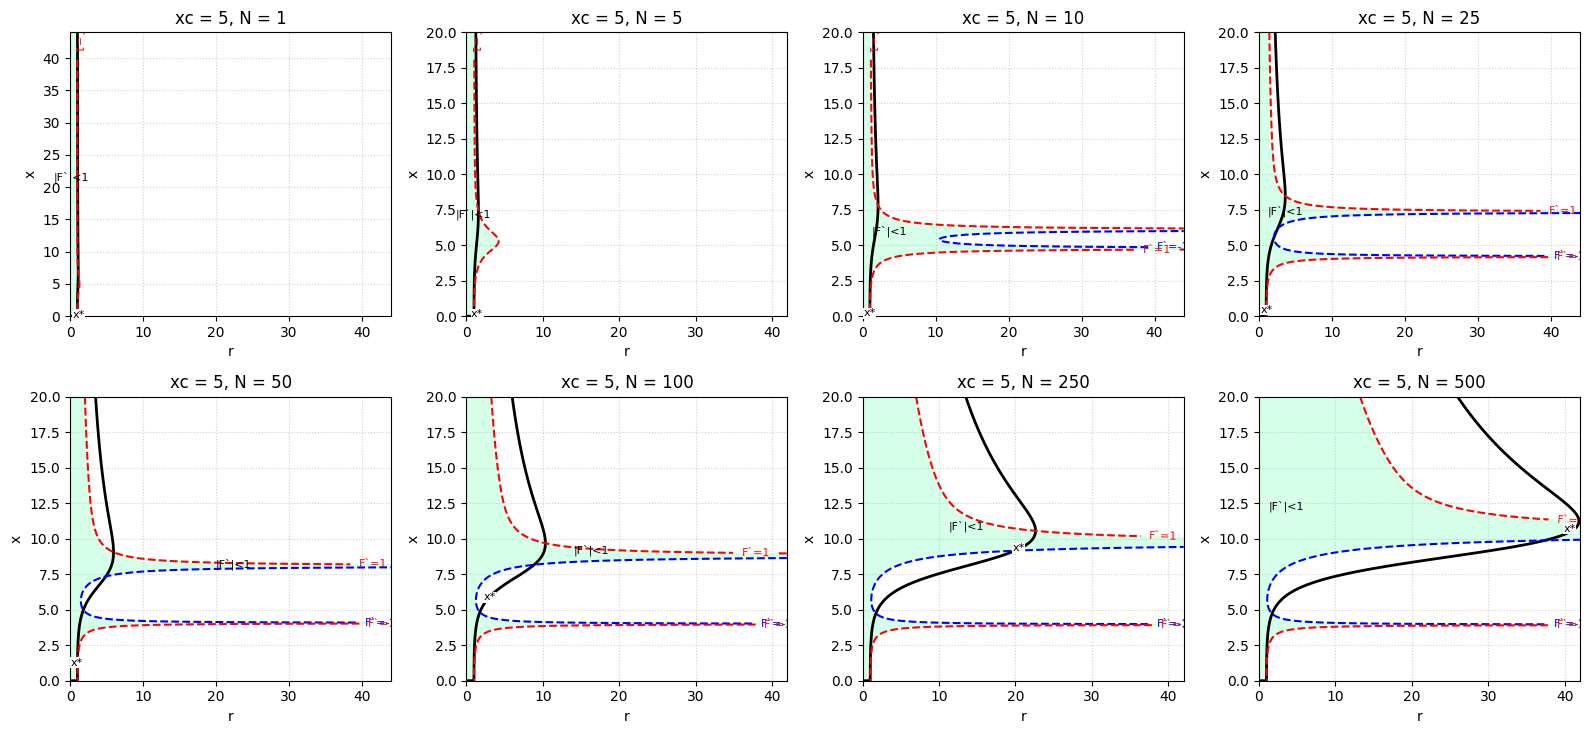

In [15]:
xc_values = [5]
N_values  = [1, 5, 10, 25, 50, 100, 250, 500]
param_sets = [
    (y,x) for y in N_values for x in xc_values 
]

x_max_map = {1: 44, 5: 20, 25: 20, 0.5: 10, 10: 20, 50: 20, 100: 20, 250: 20, 500: 20, 1000: 20}
r_max_map = {1: 44, 5: 42, 25: 44, 0.5: 4, 10: 44, 50:44, 100: 42, 250: 42, 500: 42, 1000: 80}
ncols = 4

plot_stability(param_sets, x_max_map, r_max_map, ncols, 16, 8)

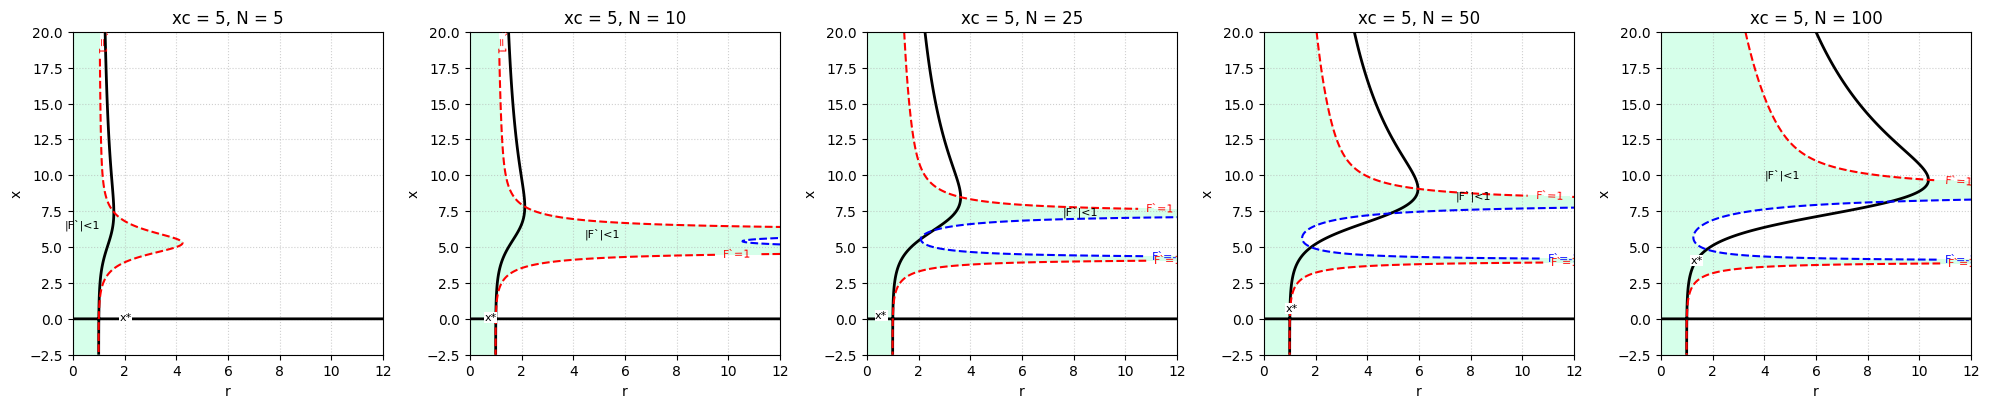

In [8]:
xc_values = [5]
N_values  = [5, 10, 25, 50, 100]

param_sets = [
    (y,x) for y in N_values for x in xc_values 
]

x_max_map = {1: 44, 5: 20, 25: 20, 0.5: 10, 10: 20, 50: 20, 100: 20, 250: 20, 500: 20, 1000: 20}
r_max_map = {1: 12, 5: 12, 25: 12, 0.5: 4, 10: 12, 50:12, 100: 12, 250: 12, 500: 12, 1000: 80}
ncols = 5

plot_stability(param_sets, x_max_map, r_max_map, ncols, 20, 4.5)

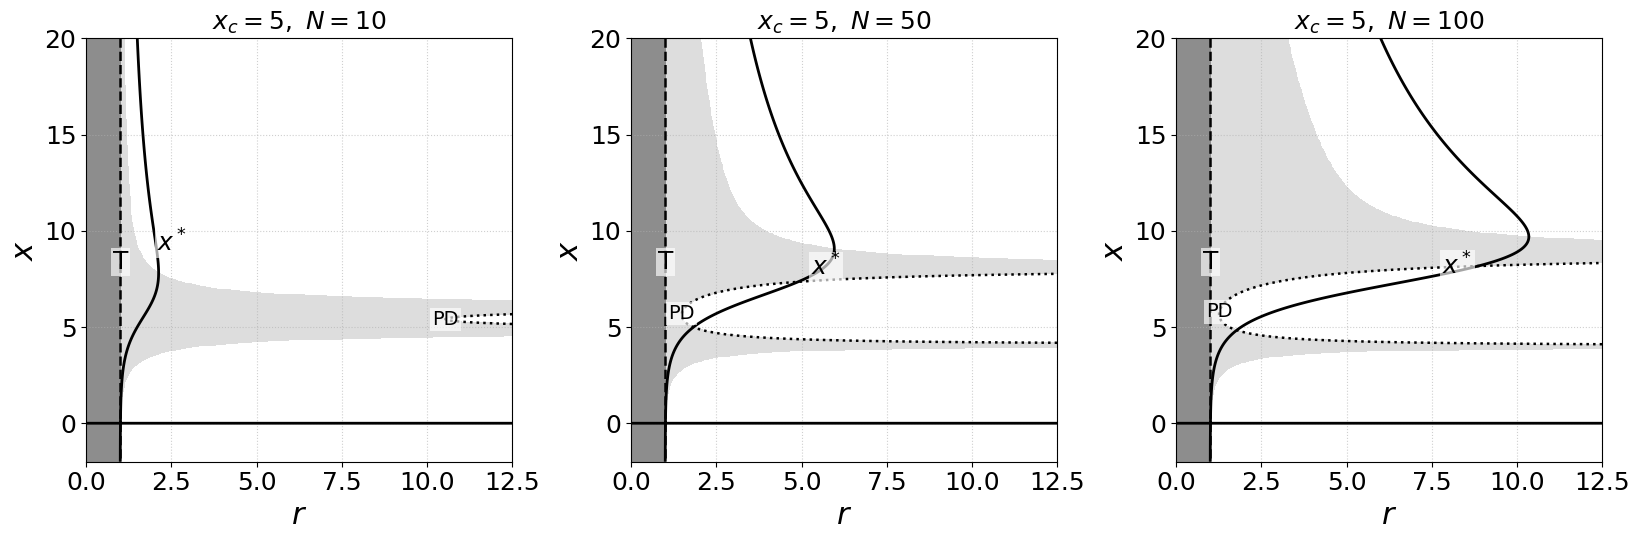

In [70]:
param_sets = [
    (10, 5),
    (50, 5),
    (100, 5),
]

plot_stability(
    param_sets,
    x_range=(-2, 20),
    r_range=(0, 12.5),
    ncols=3,
    n=500
)

D:\Temp\ipykernel_16176\3726264116.py:2: RuntimeWarning: overflow encountered in scalar multiply
  return r*x*(1 - 1/(1 + np.exp(xc - x))
D:\Temp\ipykernel_16176\3726264116.py:3: RuntimeWarning: invalid value encountered in scalar divide
  + x/((1 + np.exp(xc - x))*(N + x)))


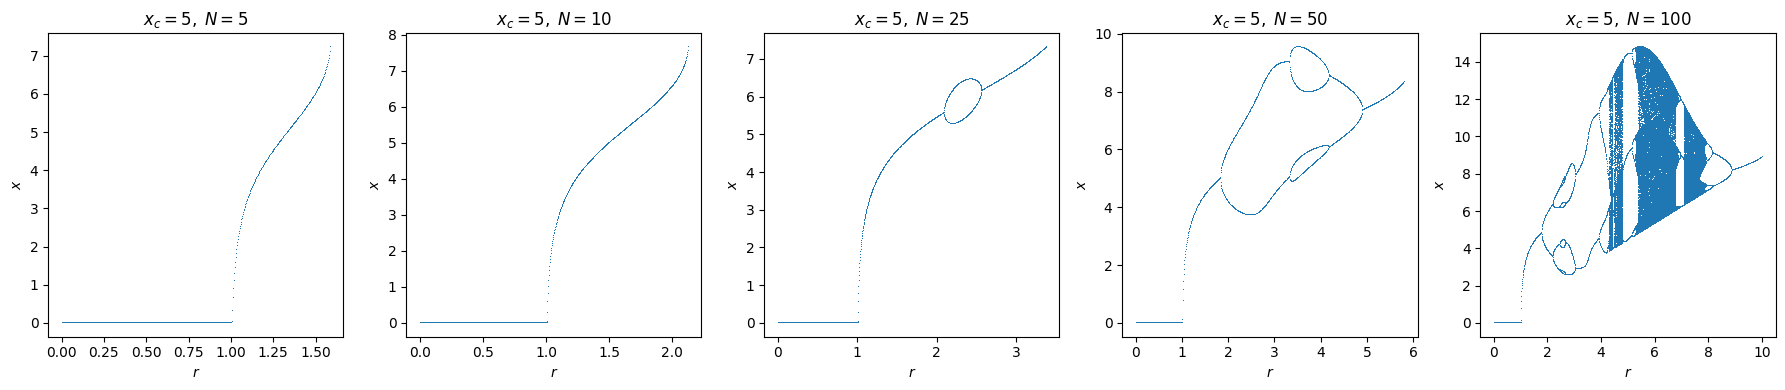

In [206]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))

xc = 5
N_values  = [5, 10, 25, 50, 100]

for j, N in enumerate(N_values):
    r_bifurcation_ax(axes[j], xc, N, 4.5 if N < 50 else 10, 4 if N < 50 else 10)

plt.tight_layout()
plt.show()

D:\Temp\ipykernel_11564\3154268734.py:12: RuntimeWarning: overflow encountered in scalar multiply
  return r * x * (
D:\Temp\ipykernel_11564\3154268734.py:14: RuntimeWarning: invalid value encountered in scalar divide
  + x / ((1 + np.exp(xc - x)) * (N + x))


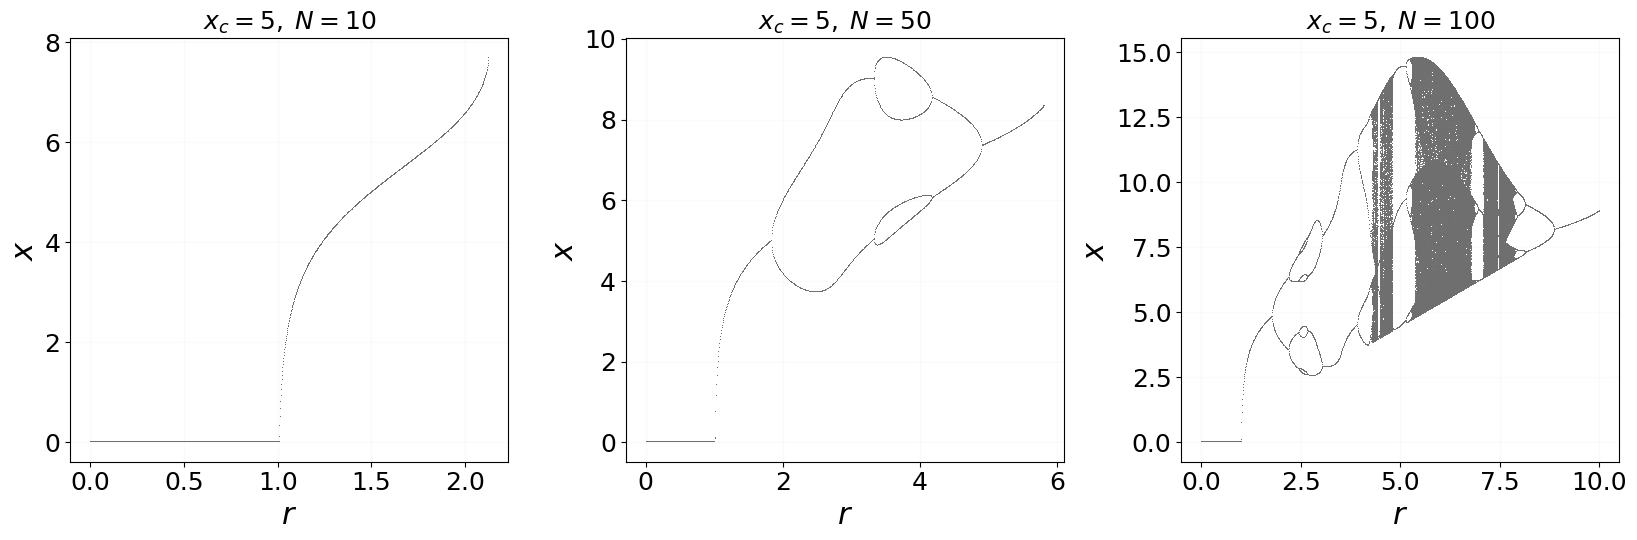

In [32]:
# ax, xc_val, N_val, x_start, r_max = 5, n_transient=3000, n_plot=300, n_r=1000
fig, axes = plt.subplots(1, 3, figsize=(16.5, 5.5))

xc = 5
N_values  = [10, 50, 100]

for j, N in enumerate(N_values):
    r_bifurcation_ax_bw(axes[j], xc, N, 2.5 if N < 50 else 10, 2.5 if N < 50 else 10, n_transient=3000, n_plot=500, n_r=1500)

plt.tight_layout()
plt.show()

D:\Temp\ipykernel_9956\3380830380.py:2: RuntimeWarning: overflow encountered in scalar multiply
  return r*x*(1 - 1/(1 + np.exp(xc - x))
D:\Temp\ipykernel_9956\3380830380.py:3: RuntimeWarning: invalid value encountered in scalar divide
  + x/((1 + np.exp(xc - x))*(N + x)))


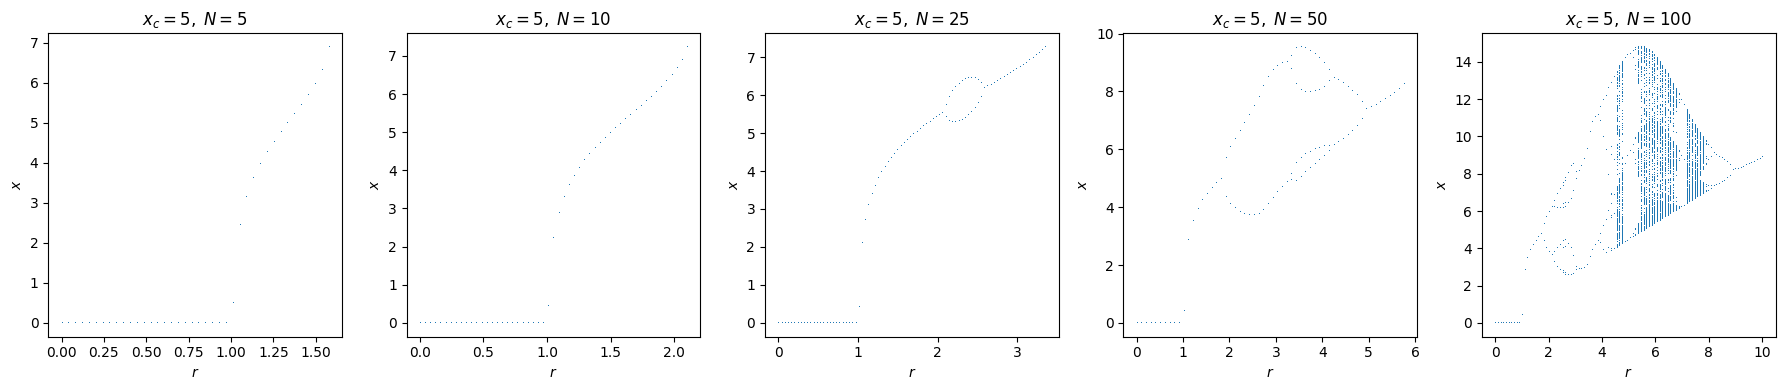

In [26]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))

xc = 5
N_values  = [5, 10, 25, 50, 100]

for j, N in enumerate(N_values):
    r_bifurcation_ax(axes[j], xc, N, 4.5 if N < 50 else 10, 4 if N < 50 else 10)

plt.tight_layout()
plt.show()

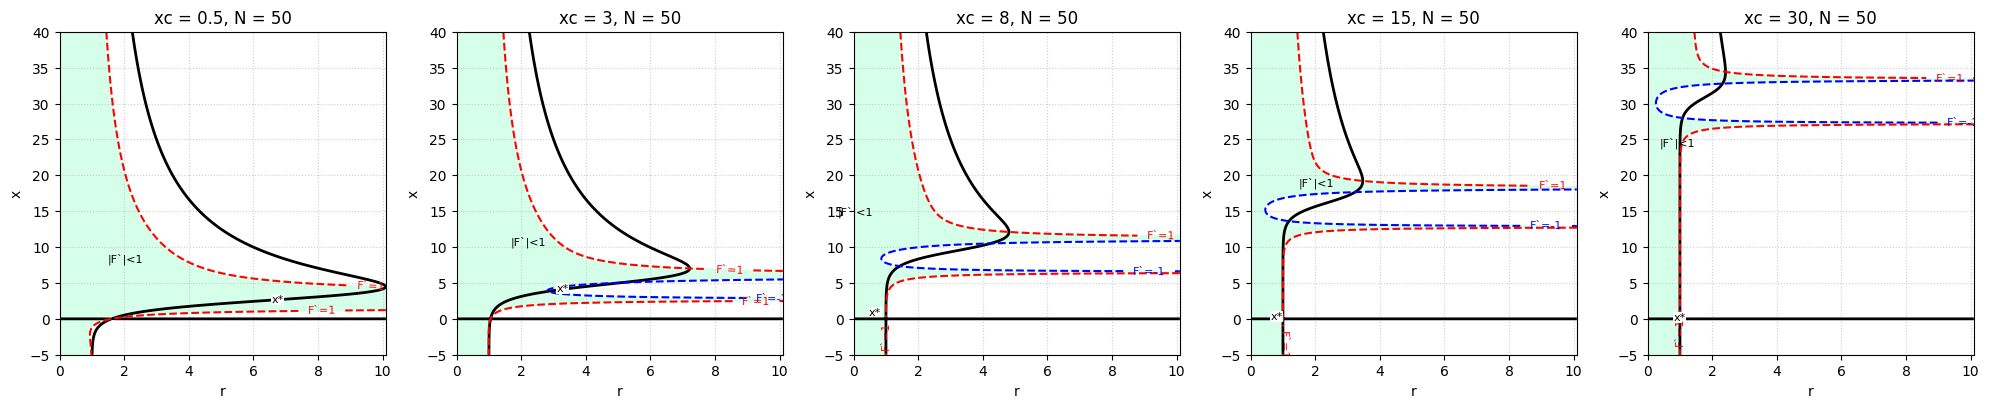

In [5]:
xc_values = [0.5, 3, 8, 15, 30]
N_values  = [50]
param_sets = [
    (y,x) for y in N_values for x in xc_values 
]

x_max_map = {1: 10, 25: 30, 0.5: 10, 10: 25, 50: 40, 100: 50, 250: 50, 500: 50, 1000: 50}
r_max_map = {1: 5, 25: 10, 0.5: 4, 10: 14, 50: 10.1, 100: 16, 250: 40, 500: 67, 1000: 150}
ncols = 5

plot_stability(param_sets, x_max_map, r_max_map, ncols, 20, 4.5)

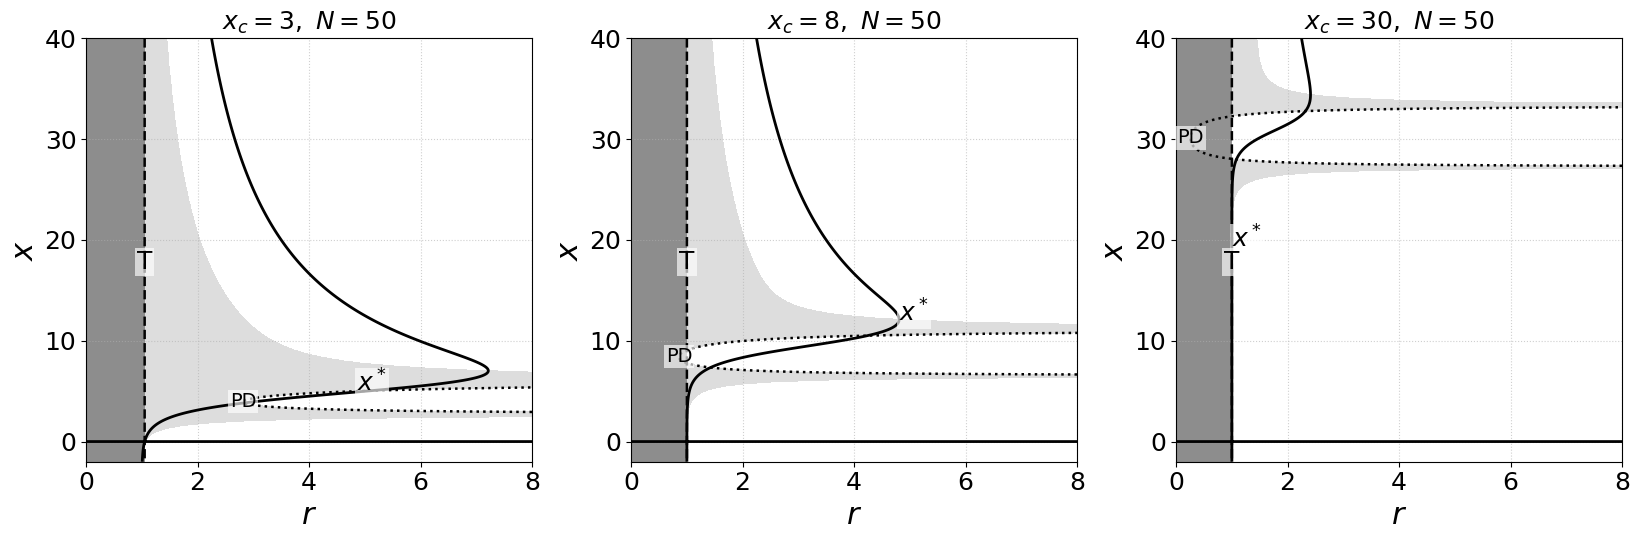

In [29]:
param_sets = [
    (50, 3),
    (50, 8),
    (50, 30),
]

plot_stability(
    param_sets,
    x_range=(-2, 40),
    r_range=(0, 8),
    ncols=3,
    n=1500
)

D:\Temp\ipykernel_16176\3726264116.py:2: RuntimeWarning: overflow encountered in scalar multiply
  return r*x*(1 - 1/(1 + np.exp(xc - x))
D:\Temp\ipykernel_16176\3726264116.py:3: RuntimeWarning: invalid value encountered in scalar divide
  + x/((1 + np.exp(xc - x))*(N + x)))


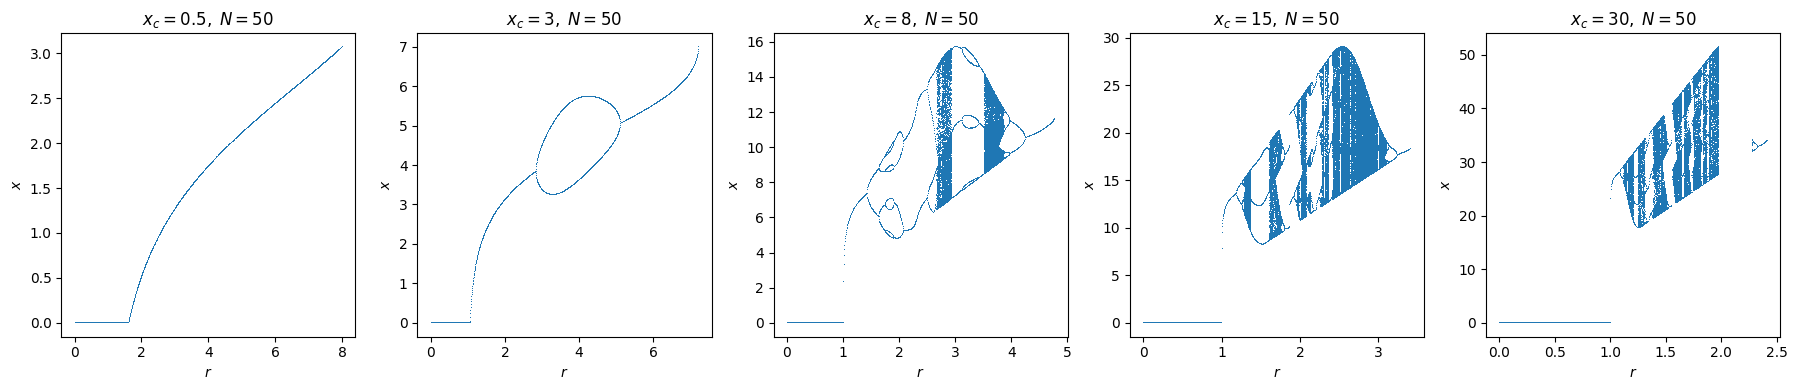

In [207]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))

N = 50
xc_values  = [0.5, 3, 8, 15, 30]

for j, xc in enumerate(xc_values):
    r_bifurcation_ax(axes[j], xc, N, 6 if xc != 8 else 10, 8 if xc < 10 else 4)

plt.tight_layout()
plt.show()

D:\Temp\ipykernel_11564\3154268734.py:12: RuntimeWarning: overflow encountered in scalar multiply
  return r * x * (
D:\Temp\ipykernel_11564\3154268734.py:14: RuntimeWarning: invalid value encountered in scalar divide
  + x / ((1 + np.exp(xc - x)) * (N + x))


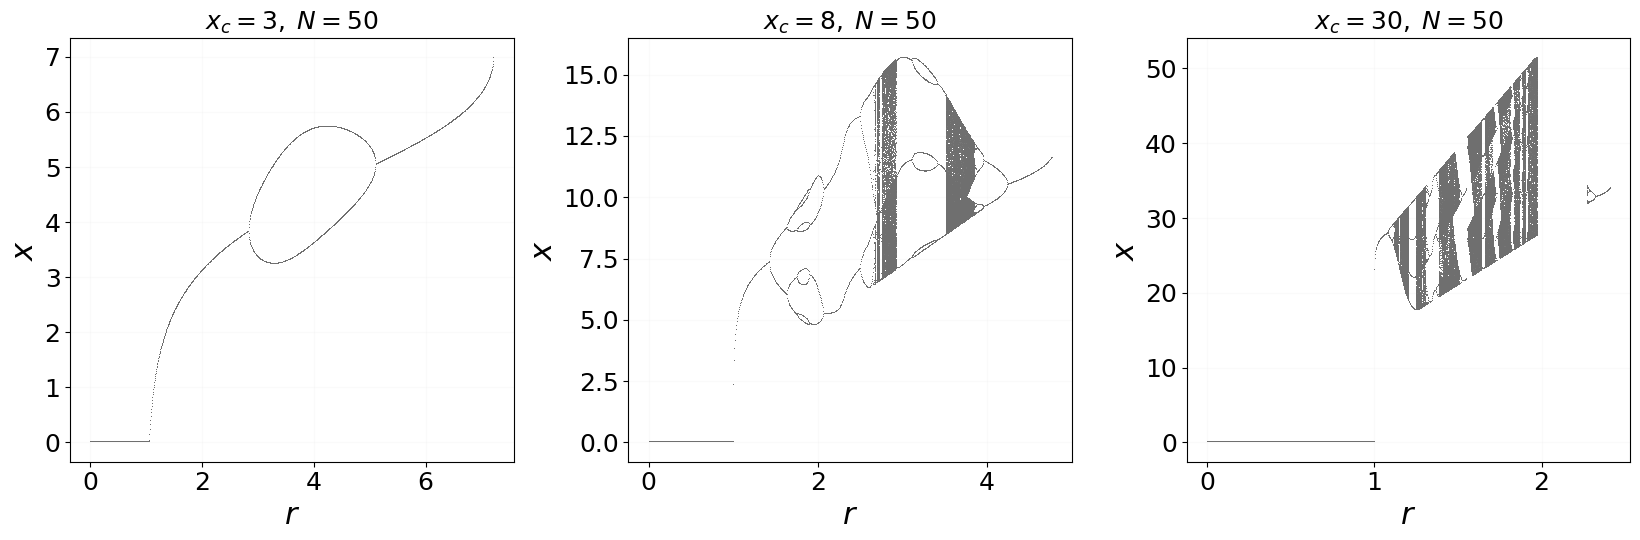

In [31]:
# ax, xc_val, N_val, x_start, r_max = 5, n_transient=3000, n_plot=300, n_r=1000
fig, axes = plt.subplots(1, 3, figsize=(16.5, 5.5))

N = 50
xc_values  = [3, 8, 30]

for j, xc in enumerate(xc_values):
    r_bifurcation_ax_bw(axes[j], xc, N, 6 if xc != 8 else 10, 8 if xc < 10 else 3, n_transient=3000, n_plot=500, n_r=1500)

plt.tight_layout()
plt.show()

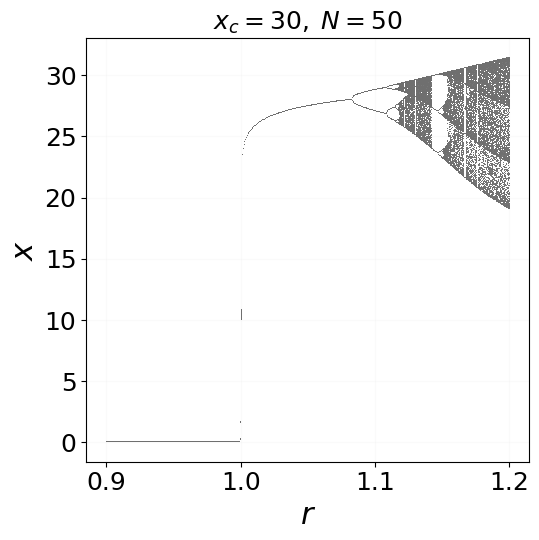

In [28]:
# ax, xc_val, N_val, x_start, r_max = 5, n_transient=3000, n_plot=300, n_r=1000
fig, axes = plt.subplots(1, 1, figsize=(5.5, 5.5))

N = 50
xc_values  = [30]

for j, xc in enumerate(xc_values):
    r_bifurcation_ax_bw(axes, xc, N, 3, 1.2, 0.9, n_transient=3000, n_plot=200, n_r=500)

plt.tight_layout()
plt.show()

D:\Temp\ipykernel_9956\3380830380.py:2: RuntimeWarning: overflow encountered in scalar multiply
  return r*x*(1 - 1/(1 + np.exp(xc - x))
D:\Temp\ipykernel_9956\3380830380.py:3: RuntimeWarning: invalid value encountered in scalar divide
  + x/((1 + np.exp(xc - x))*(N + x)))


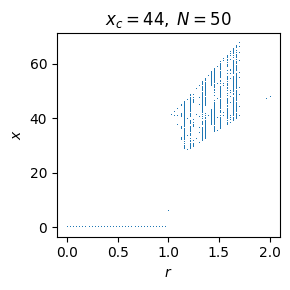

In [24]:
fig, axes = plt.subplots(1, 1, figsize=(3, 3))

N = 50
xc_values  = [44]

for j, xc in enumerate(xc_values):
    r_bifurcation_ax(axes, xc, N, 6, 3)

plt.tight_layout()
plt.show()

# Рассмотрим случай N = 50, xc = 5 (рисунок [0,3]). r = 5.2, по графику при этом r существует 2 решения - подберем точки в окрестности этих решений и посмотрим их устойчивость


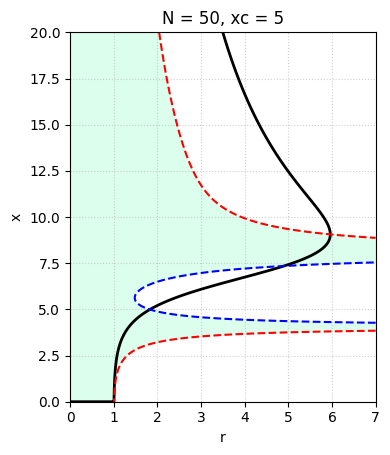

In [56]:
def draw_1xr(xc, N0, r_max, x_max):
    def F(x, r, N, xc):
        return r*x*(1 - 1/(1 + np.exp(xc - x))
                    + x/((1 + np.exp(xc - x))*(N + x)))
    
    def dF_dx(x, r, N, xc, h=1e-6):
        return (F(x+h, r, N, xc) - F(x-h, r, N, xc)) / (2*h)
    xc_values = [xc]
    N_values  = [N0]
    param_sets = [(y,x) for y in N_values for x in xc_values]
    fig, ax = plt.subplots(1, 1, figsize=(4, 5))
    
    for (N, xc) in param_sets:
        x = np.linspace(0, x_max, 1200)
        r = np.linspace(0, r_max, 1200)
        R, X = np.meshgrid(r, x)
    
        G = X - F(X, R, N, xc)
        dF = dF_dx(X, R, N, xc)
        stable = (dF > -1) & (dF < 1)
    
        ax.contourf(
            R, X, stable,
            levels=[0.5, 1],
            colors=['#ccffe5'],
            alpha=0.7
        )
        ax.contour(R, X, G, levels=[0], colors='black', linewidths=2)
        ax.contour(R, X, dF, levels=[-1], colors='blue', linestyles='dashed')
        ax.contour(R, X, dF, levels=[1], colors='red', linestyles='dashed')
        
        ax.set_title(f"N = {N}, xc = {xc}")
        ax.set_xlabel("r")
        ax.set_ylabel("x")
        ax.grid(True, linestyle=":", alpha=0.6)
    plt.tight_layout(rect=[0, 0, 1, 0.93])
    plt.show()
draw_1xr(5, 50, 7, 20)

In [53]:
def f(x, xc):
    return 1.0 / (1.0 + np.exp(xc - x))
def m(x, N):
    return x / (N + x)
def Xn(x, r, N, xc = 5):
    F = f(x, xc)
    M = m(x, N)
    return (1 - F + F * M) * r * x

def r_tragectory(ax, xc_val, N_val, r_val, x0):
    N0 = N_val
    xc = xc_val
    r = r_val
    R = []
    X = []
    x = x0
    for n in range(125):
        x = Xn(x, r, N0, xc)
        R.append(n)
        X.append(x)
    ax.plot(R, X, ls='', marker='.')
    ax.set_title(f'x_c = {xc_val}, N = {N_val}, r= {r_val}, x_start = {x0}')
    ax.set_xlabel('$n$')
    ax.set_ylabel('$x_n$')

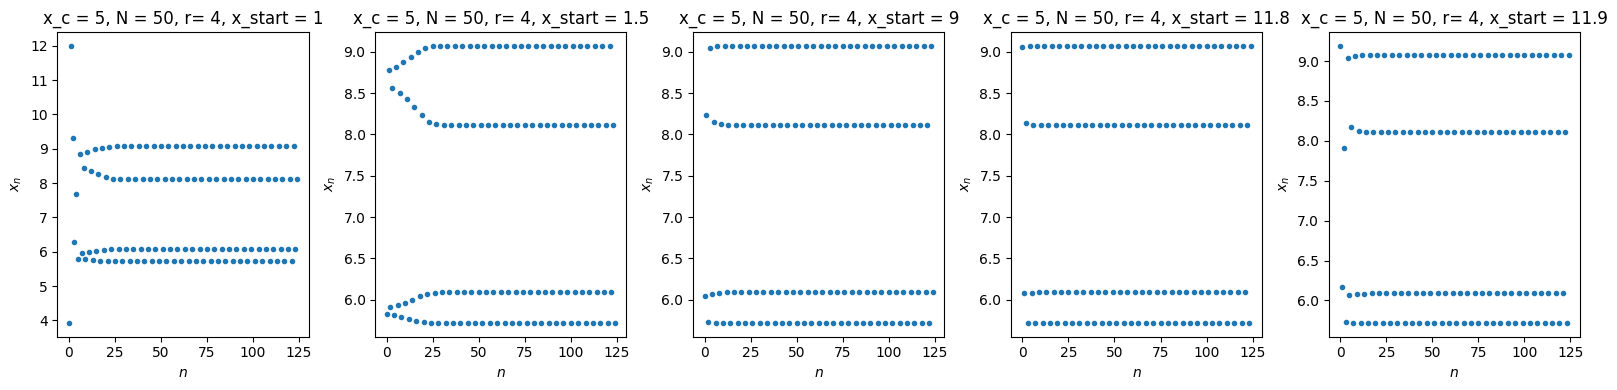

In [4]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
x0_values = [1, 1.5, 9, 11.8, 11.9]

for i, x0 in enumerate(x0_values):
    r_tragectory(axes[i], 5, 50, 4, x0)

plt.tight_layout()
plt.show()

D:\Temp\ipykernel_7092\2042315172.py:8: RuntimeWarning: overflow encountered in scalar multiply
  return (1 - F + F * M) * r * x
D:\Temp\ipykernel_7092\2042315172.py:4: RuntimeWarning: invalid value encountered in scalar divide
  return x / (N + x)


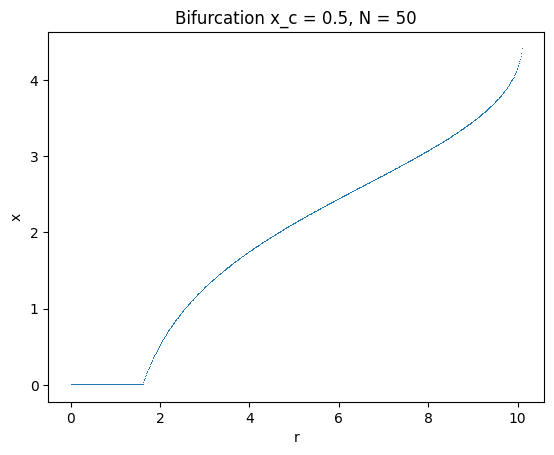

In [47]:
r_bifurcation(0.5, 50, 1, 12)

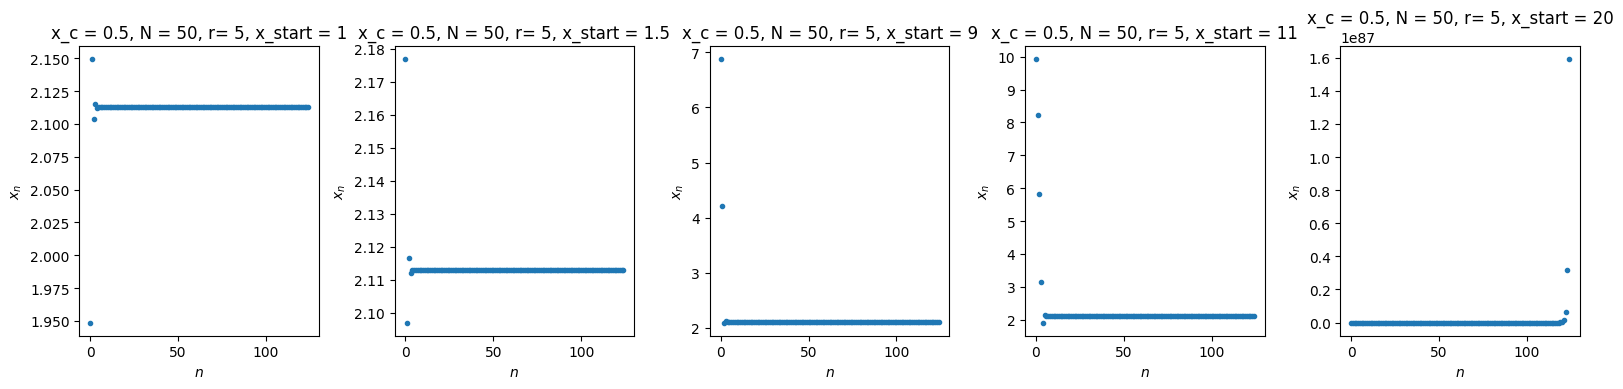

In [55]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
x0_values = [1, 1.5, 9, 11, 20]

for i, x0 in enumerate(x0_values):
    r_tragectory(axes[i], 0.5, 50, 5, x0)

plt.tight_layout()
plt.show()

D:\Temp\ipykernel_7092\2042315172.py:8: RuntimeWarning: overflow encountered in scalar multiply
  return (1 - F + F * M) * r * x
D:\Temp\ipykernel_7092\2042315172.py:4: RuntimeWarning: invalid value encountered in scalar divide
  return x / (N + x)


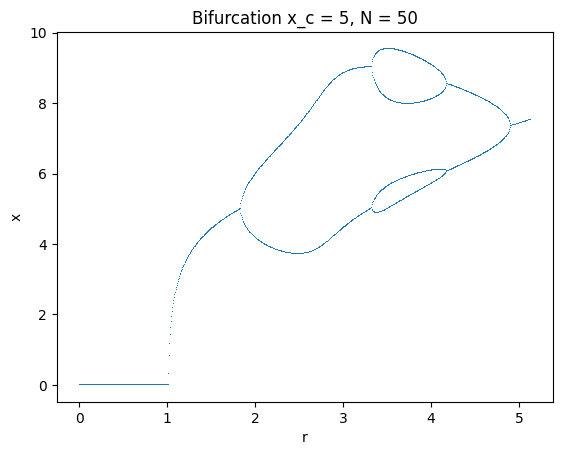

In [48]:
r_bifurcation(5, 50, 0.5, 6)

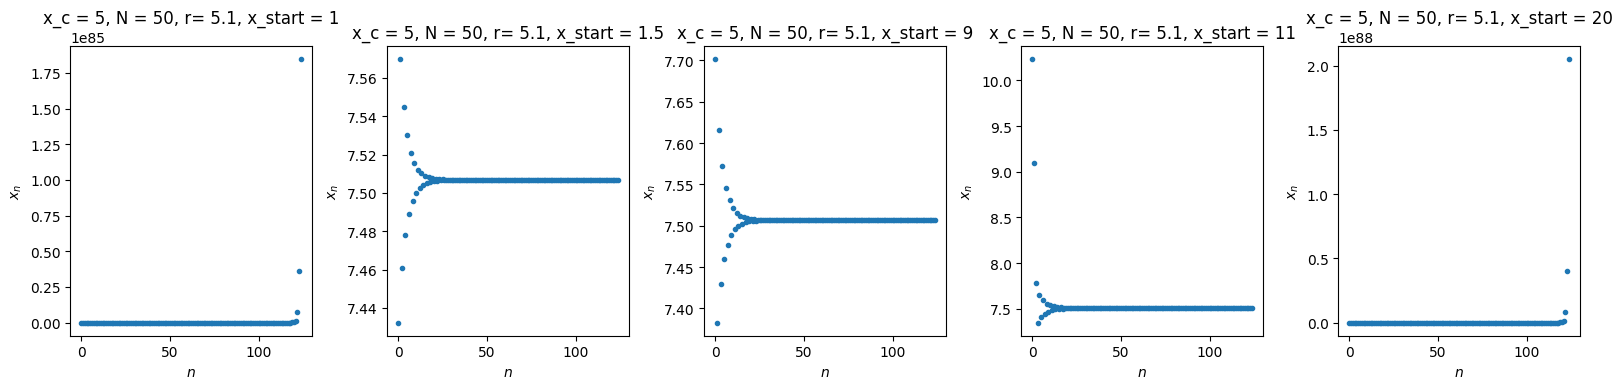

In [7]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
x0_values = [1, 1.5, 9, 11, 20]

for i, x0 in enumerate(x0_values):
    r_tragectory(axes[i], 5, 50, 5.1, x0)

plt.tight_layout()
plt.show()

# А вот случай N = 100, xc = 2.5 должен нормально и по бифуркациям и по графикам получиться


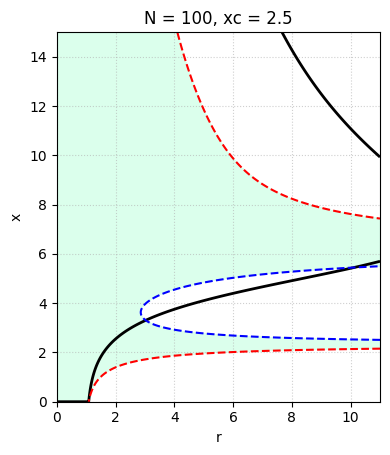

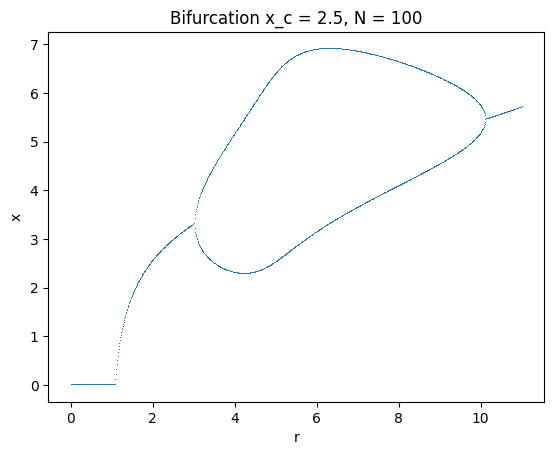

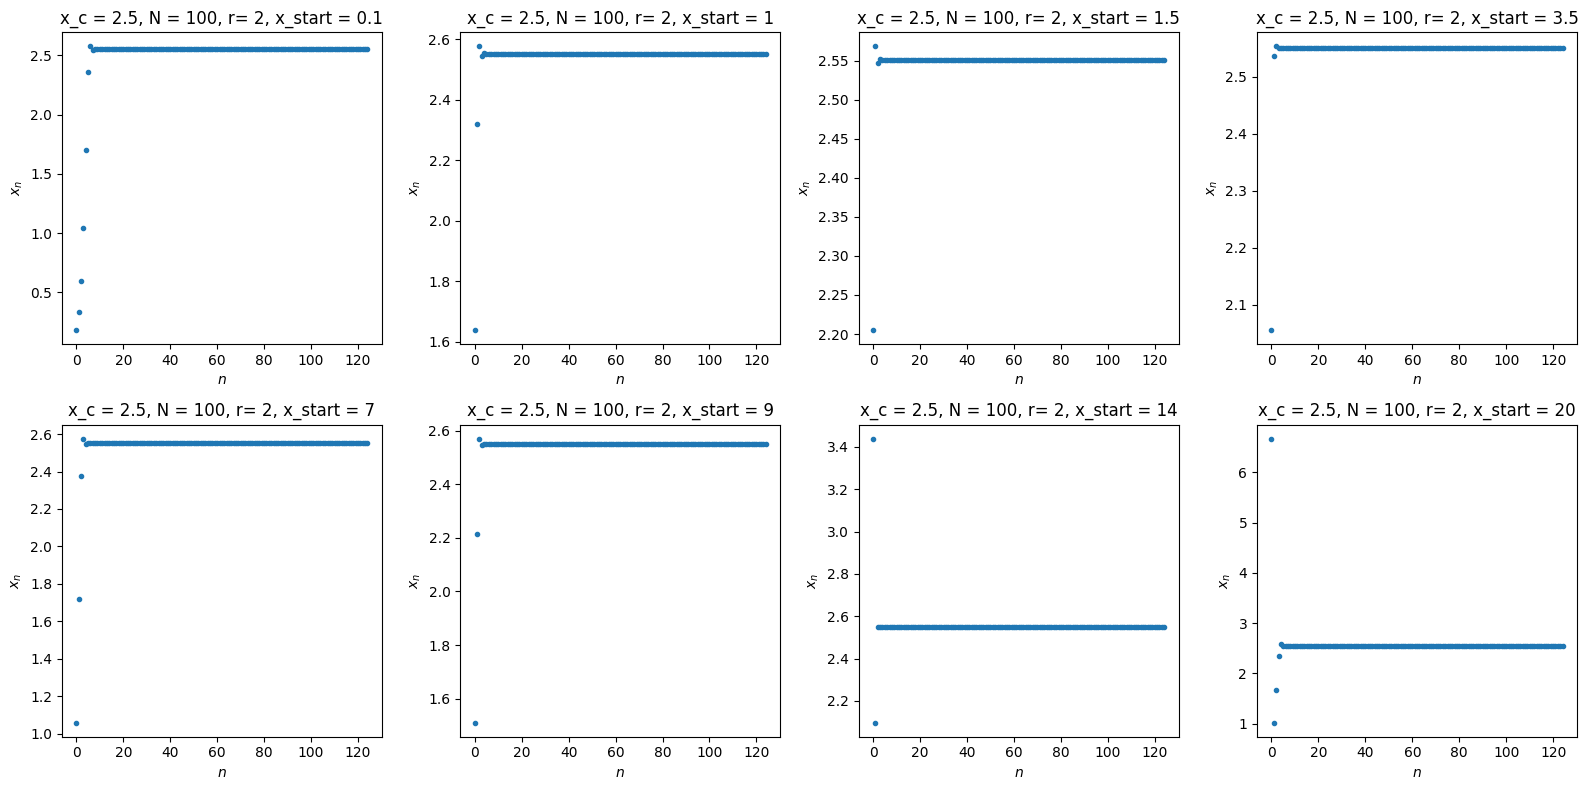

In [58]:
draw_1xr(xc=2.5, N0=100, r_max=11, x_max=15)
r_bifurcation(xc_val=2.5, N_val=100, x_start=1, r_max=11)

x0_values = [0.1, 1, 1.5, 3.5, 7, 9, 14, 20]
fig, axes = plt.subplots(2, len(x0_values) // 2, figsize=(16, 8))
for i, x0 in enumerate(x0_values[:len(x0_values) // 2]):
    r_tragectory(axes[0, i], 2.5, 100, 2, x0)
for i, x0 in enumerate(x0_values[len(x0_values) // 2:]):
    r_tragectory(axes[1, i], 2.5, 100, 2, x0)
plt.tight_layout()
plt.show()

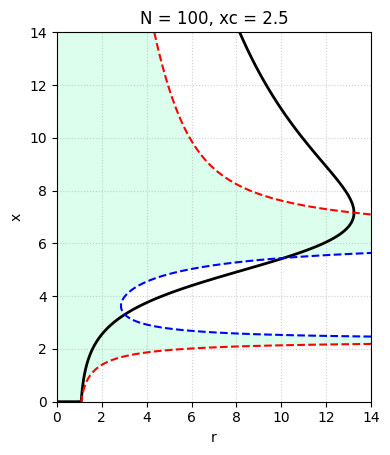

D:\Temp\ipykernel_7092\2042315172.py:8: RuntimeWarning: overflow encountered in scalar multiply
  return (1 - F + F * M) * r * x
D:\Temp\ipykernel_7092\2042315172.py:4: RuntimeWarning: invalid value encountered in scalar divide
  return x / (N + x)


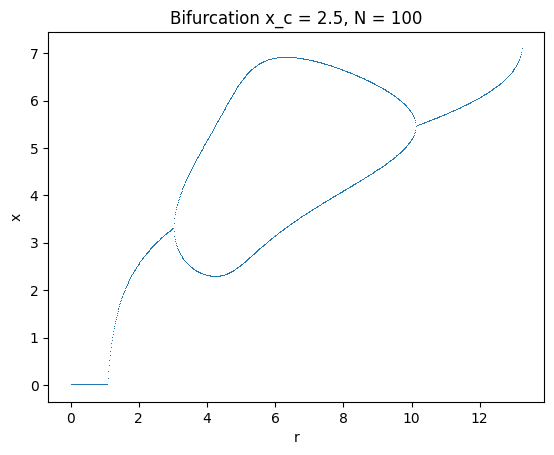

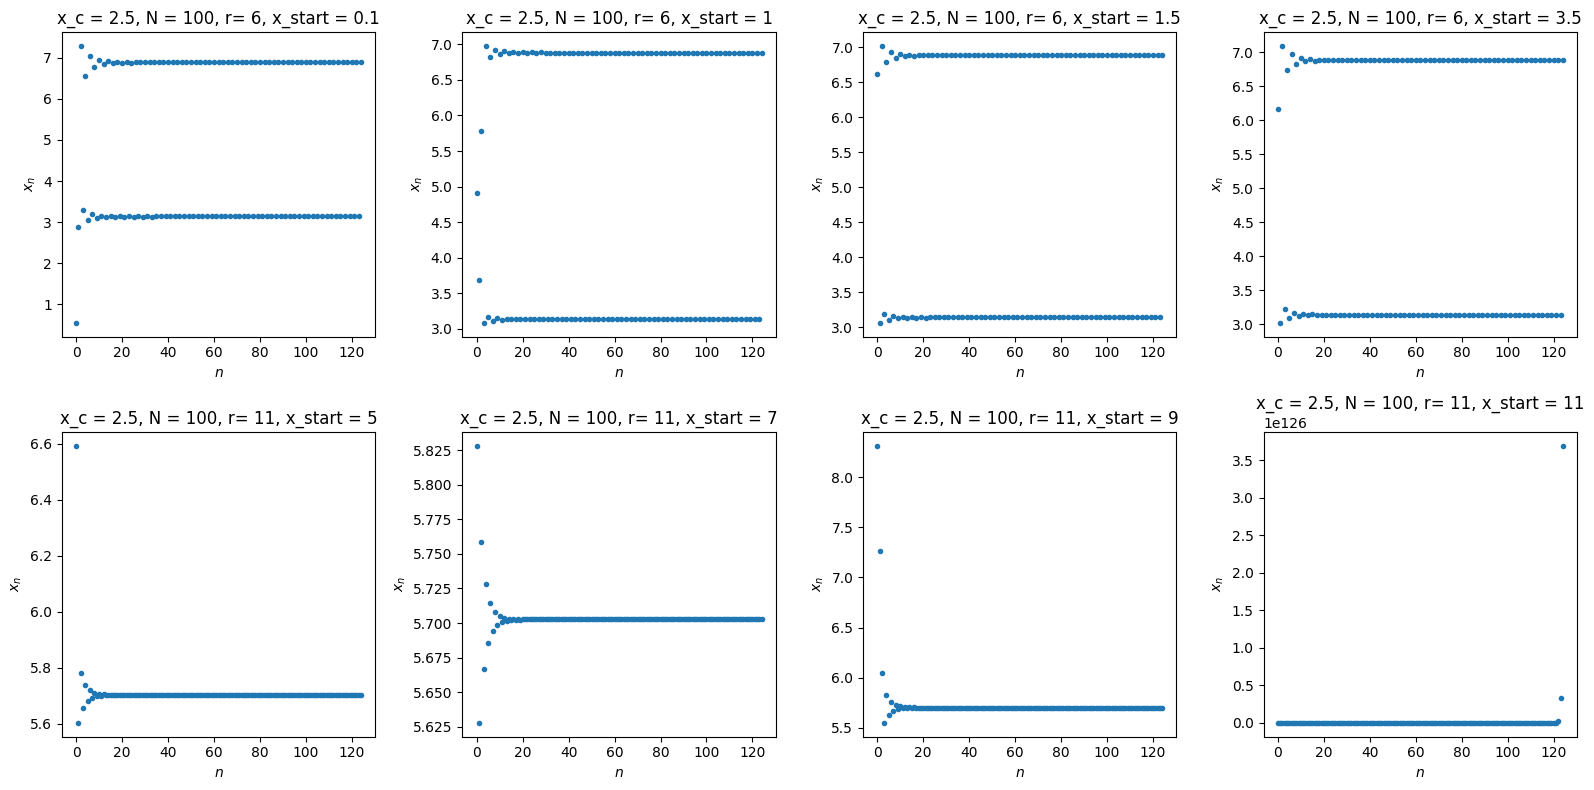

In [65]:
draw_1xr(xc=2.5, N0=100, r_max=14, x_max=14)
r_bifurcation(xc_val=2.5, N_val=100, x_start=0.5, r_max=14)

x0_values = [0.1, 1, 1.5, 3.5, 5, 7, 9, 11]
fig, axes = plt.subplots(2, len(x0_values) // 2, figsize=(16, 8))
for i, x0 in enumerate(x0_values[:len(x0_values) // 2]):
    r_tragectory(axes[0, i], 2.5, 100, 6, x0)
for i, x0 in enumerate(x0_values[len(x0_values) // 2:]):
    r_tragectory(axes[1, i], 2.5, 100, 11, x0)
plt.tight_layout()
plt.show()

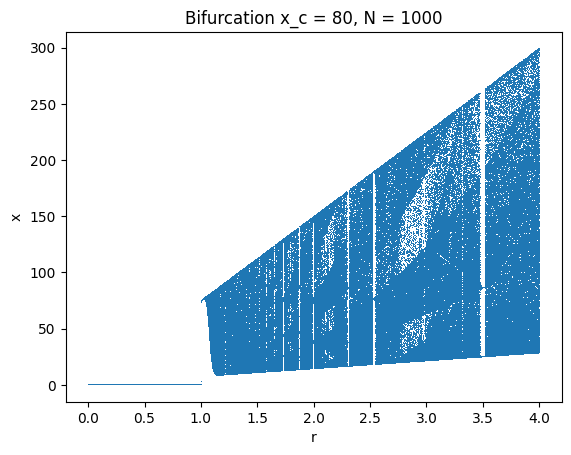

In [15]:
r_bifurcation(80, 1000, 1, 4)